# HW1 — `bioresponse` classification

Goal: use `Activity` as the target variable and the molecular descriptors as features, train four classifiers, compare their metrics, and select a model/threshold with `Recall > 0.95`.

## Student information

- **Name:** Oleg Yurchik
- **Group:** J4133
- **Assignment:** HW1



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_curve, auc, precision_recall_curve,
    average_precision_score)

DATA = Path('./bioresponse.csv')
OUT = Path('results')
OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)

## 1. Data preparation

We use a stratified 75/25 split to preserve the class balance.

In [2]:
X = df.drop(columns='Activity')
y = df['Activity']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
split_summary = pd.DataFrame({
    'split': ['train', 'test'],
    'rows': [len(X_train), len(X_test)],
    'positive_rate': [y_train.mean(), y_test.mean()],
}).set_index('split')
split_summary.round(4)

,rows,positive_rate
split,,
train,2813,0.5421
test,938,0.5426


## 2. Four classifiers

We compare shallow and deep decision trees and random forests built from shallow and deep trees.

In [3]:
models = {
    'small_tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'deep_tree': DecisionTreeClassifier(random_state=42),
    'forest_small': RandomForestClassifier(n_estimators=300, max_depth=4, random_state=42, n_jobs=-1),
    'forest_deep': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
scores = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    scores[name] = proba
    fpr, tpr, _ = roc_curve(y_test, proba)
    rows.append({
        'model': name, 'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred),
        'log_loss': log_loss(y_test, proba), 'roc_auc': auc(fpr, tpr),
    })
metrics = pd.DataFrame(rows).set_index('model').sort_values('f1', ascending=False)
metrics.round(4)

,accuracy,precision,recall,f1,log_loss,roc_auc
model,,,,,,
forest_deep,0.7783,0.7845,0.8153,0.7996,0.4734,0.8603
small_tree,0.7495,0.7605,0.7859,0.7729,0.7080,0.7652
deep_tree,0.7090,0.7169,0.7662,0.7407,10.4903,0.7036
forest_small,0.7068,0.7233,0.7446,0.7338,0.5825,0.7901


## 3. ROC and precision–recall curves

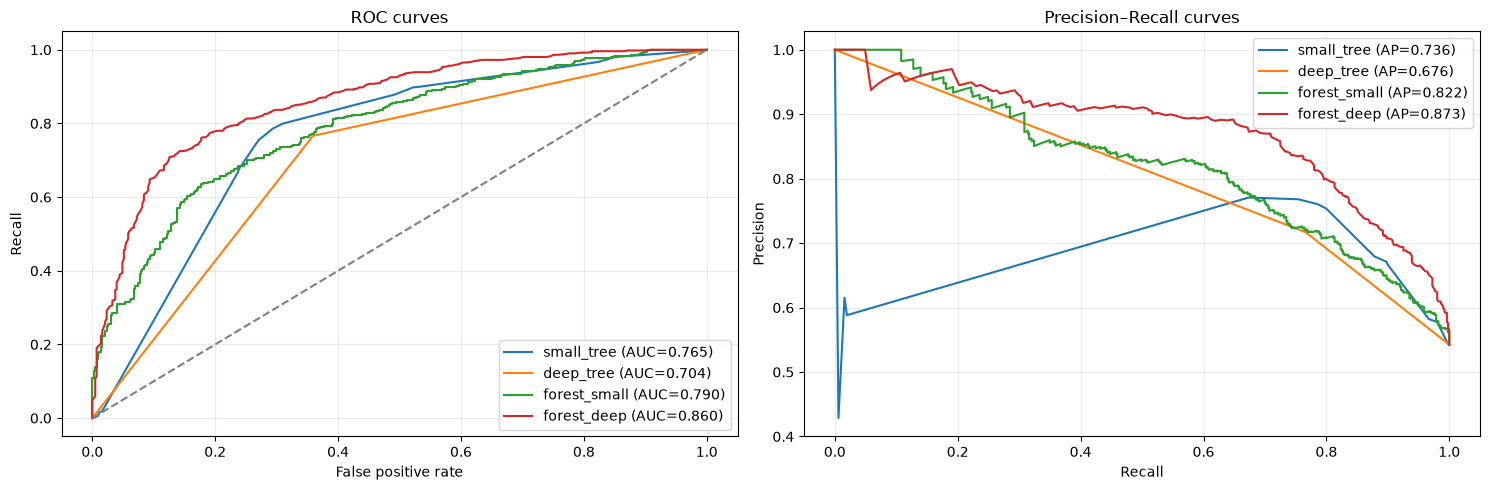

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, proba in scores.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc(fpr, tpr):.3f})')
    precision, recall, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_test, proba):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='False positive rate', ylabel='Recall', title='ROC curves')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall curves')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
fig.savefig(OUT / 'hw1_curves.png', dpi=160, bbox_inches='tight')

## 4. A model with few False Negatives

For the deep forest, we select the highest threshold that still gives `Recall >= 0.95`. Lowering the threshold usually increases recall while reducing precision and accuracy.

In [5]:
best_name = 'forest_deep'
proba = scores[best_name]
precision, recall, thresholds = precision_recall_curve(y_test, proba)
valid = thresholds[recall[:-1] >= 0.95]
threshold = float(valid[-1]) if len(valid) else 0.5
pred = (proba >= threshold).astype(int)
high_recall = pd.DataFrame([{
    'model': best_name, 'threshold': threshold,
    'accuracy': accuracy_score(y_test, pred),
    'precision': precision_score(y_test, pred, zero_division=0),
    'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred),
    'log_loss': log_loss(y_test, proba),
}])
metrics.to_csv(OUT / 'metrics.csv')
high_recall.to_csv(OUT / 'high_recall_model.csv', index=False)
high_recall.round(4)

,model,threshold,accuracy,precision,recall,f1,log_loss
0,forest_deep,0.2933,0.7143,0.6653,0.9528,0.7835,0.4734


## Error analysis

The high-recall classifier uses the deep random forest probabilities with a lower decision threshold. This threshold is a deliberate classification rule: it prioritizes avoiding Type II errors (False Negatives), even at the cost of more False Positives.

In [6]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
error_summary = pd.DataFrame({
    'count': [tn, fp, fn, tp],
    'meaning': ['Correct negative', 'False Positive (Type I)', 'False Negative (Type II)', 'Correct positive'],
}, index=['TN', 'FP', 'FN', 'TP'])
error_summary

,count,meaning
TN,185,Correct negative
FP,244,False Positive (Type I)
FN,24,False Negative (Type II)
TP,485,Correct positive


## Conclusion

The experiments compare four classifiers for the binary `bioresponse` task. The best model is selected using validation performance rather than a single metric. Because the assignment requires recall above 0.95, the decision threshold is adjusted instead of relying automatically on 0.5. This improves the ability to detect positive responses, but it may reduce precision and increase false positives. Therefore, the final model should be reported with precision, recall, F1-score, confusion matrix, and the number of false negatives. The results show why threshold selection and the business cost of missed positives are more important here than maximizing accuracy alone.
